# Variant Well Profiles

In [58]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl

## Loading data

### Read in the classifier metrics

In [10]:
# Paths
metrics_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect"
batches = ["2024_01_23_Batch_7", "2024_02_06_Batch_8"]
thresh = 3

metrics_df, metrics_wtvar = pl.DataFrame(), pl.DataFrame()
for batch in batches:
    met_dir = metrics_dir.format(batch)
    metrics_df_batch = pl.read_csv(f"{met_dir}/metrics.csv")
    metrics_wtvar_batch = pl.read_csv(f"{met_dir}/metrics_summary.csv")

    metrics_df = pl.concat([metrics_df, metrics_df_batch])
    metrics_wtvar = pl.concat([metrics_wtvar, metrics_wtvar_batch])

## get the localization metrics
local_wtvar = metrics_wtvar.filter(pl.col("Classifier_type") == "localization")

## get the alleles and their reference genes
local_wtvar = local_wtvar.with_columns(
    pl.when(pl.col("AUROC_mean") > pl.col("AUROC_thresh"))
    .then(1)
    .otherwise(0)
    .alias("mislocalized")
).unique()
misloc_alleles = (
    local_wtvar
    .select("allele_0")
    .to_series()
    .to_list()
)
misloc_wt = (
    local_wtvar
    .with_columns(pl.col("allele_0").str.replace("_.*", "").alias("wt"))
    .select("wt")
    .to_series()
    .unique()
    .to_list()
)
all_alleles = misloc_alleles + misloc_wt

## get individual classifiers pass the training imbalance threshold
ind_class = metrics_df.filter(
    (~pl.col("Metadata_Control"))
    & (pl.col("Training_imbalance") < thresh)
    & (
        (pl.col("Full_Classifier_ID").str.contains("true"))
        & pl.col("allele_0").is_in(misloc_alleles)
    )
)

In [37]:
misloc_binary = (
    local_wtvar.pivot(
        index=["allele_0", "Allele_set"], ## , "AUROC_mean"
        on="Batch",
        values="mislocalized",
    )
    .with_columns(
        ((pl.col("B7") == 1) & (pl.col("B8") == 1)).alias(
            "mislocalized_both_batches"
        )
    )
    .rename({"B7": "mislocalized_batch7", "B8": "mislocalized_batch8"})
)

misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]

allele_0
str
"""KCTD7_Arg94Trp"""
"""PMP22_Asp37Val"""
"""HBD_Glu27Asp"""
"""XPA_Cys108Phe"""
"""ACSF3_Pro243Leu"""
…
"""PLP1_Ile152Thr"""
"""EMD_Ala56Thr"""
"""PNPO_Arg95Cys"""


### Read in cell profiles

In [11]:
# Paths
profile_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles"
pass_qc_prof_dir = f"{profile_dir}/" + "{}/profiles_tcdropped_filtered_var_mad_outlier_featselect.parquet"

# Get meta features
b7_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[0])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

b8_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[1])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

cell_alleles = pl.concat([b7_alleles.collect(), b8_alleles.collect()])

In [12]:
prof_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles/{}/profiles.parquet"

b7_prof = pl.scan_parquet(
    prof_dir.format(batches[0])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)
b8_prof = pl.scan_parquet(
    prof_dir.format(batches[1])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)

gfp_int = [i for i in b7_prof.collect_schema().names() if "GFP" in i]
gfp_int = ["Metadata_CellID"] + gfp_int

profiles = pl.concat([
    b7_prof.select(gfp_int).collect(),
    b8_prof.select(gfp_int).collect(),
])

# This method of joining ensures that only cells past filters are included in the abundance analysis
profiles = cell_alleles.join(profiles, on="Metadata_CellID", how="left")

### Merge to well profiles

In [13]:
well_profiles = (
    profiles.group_by(["Metadata_Plate", "Metadata_Well", "Metadata_gene_allele"])
    .agg(
        pl.col(col).median().alias(col)
        for col in profiles.columns
        if not col.startswith("Metadata_")
    )
    # .drop("Metadata_CellID")
    .unique()
)

well_profiles

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_02_01_B8A1R2_P2T4""","""J03""","""IRAK4_Ala428Thr""",0.014545,-0.059896,-0.065105,-0.041361,0.155751,0.433547,0.62942,0.557408,0.489919,0.580771,0.810167,0.856924,0.056573,1.0,0.059795,0.045798,0.813564,0.819929,0.183969,0.090932,0.090701,0.090881,0.873857,4.664311,10.91608,10.941126,10.925578,1.121859,13.068297,0.062821,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2024_01_19_B7A1R1_P4T1""","""I01""","""SH3BP2_Arg415Gln""",0.334712,-0.088379,-0.09535,-0.078225,0.132988,0.406006,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.429156,0.741445,0.740471,0.739925,5.067937,0.565837,1.139368,1.137604,1.143028,0.144615,2.528843,0.285457,0.511078,0.370078,0

## Well Profiles Visualization

,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Granularity_1_GFP,...,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
Metadata_gene_allele,,,,,,,,,,,,,,,,,,,,,
KCTD7_Arg94Trp,-0.277729,-0.276740,-0.276422,-0.277243,-0.275889,0.206004,0.209406,0.206451,0.275737,0.010945,...,-0.154526,-0.149248,-0.136004,-0.123261,-0.141840,-0.125582,-0.153390,-0.156359,-0.155088,-0.155155
PMP22_Asp37Val,-0.322826,-0.308077,-0.307550,-0.308783,-0.307626,1.923735,1.923712,1.922127,2.255696,1.778500,...,-0.154589,-0.149306,-0.136004,-0.123261,-0.141840,-0.125582,-0.153452,-0.156422,-0.155155,-0.155227
HBD_Glu27Asp,-0.180874,-0.230456,-0.230260,-0.230584,-0.229167,-0.489752,-0.489348,-0.489701,0.003360,-0.633984,...,-0.151724,-0.146722,-0.133146,-0.119728,-0.138626,-0.121552,-0.150607,-0.153671,-0.152296,-0.152491
XPA_Cys108Phe,-0.259714,-0.288379,-0.287996,-0.288827,-0.284250,0.478955,0.480271,0.480841,0.496660,0.477392,...,-0.154569,-0.149287,-0.136004,-0.123261,-0.141840,-0.125582,-0.153432,-0.156396,-0.155130,-0.155207
ACSF3_Pro243Leu,-0.306985,-0.285907,-0.285440,-0.286476,-0.280607,0.320958,0.321279,0.318316,-0.147177,0.395010,...,-0.154441,-0.149198,-0.136004,-0.123261,-0.141840,-0.125582,-0.153312,-0.156275,-0.155010,-0.155074
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PLP1_Ile152Thr,-0.155646,-0.069679,-0.070647,-0.068549,-0.100228,-1.030741,-1.030059,-1.031414,-0.922753,-1.202025,...,-0.122890,-0.119766,-0.120122,-0.108856,-0.123270,-0.107400,-0.123150,-0.126976,-0.125261,-0.124402
EMD_Ala56Thr,-0.224692,-0.235408,-0.234645,-0.235547,-0.256462,-0.522834,-0.524531,-0.520660,-0.113682,-0.070570,...,-0.146069,-0.141633,-0.133810,-0.121416,-0.138633,-0.123577,-0.145240,-0.147978,-0.146182,-0.146406
PNPO_Arg95Cys,-0.179073,-0.180747,-0.180941,-0.180480,-0.169142,-0.750015,-0.749202,-0.750335,-0.728185,-0.921081,...,-0.146324,-0.141388,-0.128404,-0.116114,-0.133039,-0.117406,-0.144975,-0.147896,-0.146433,-0.146341


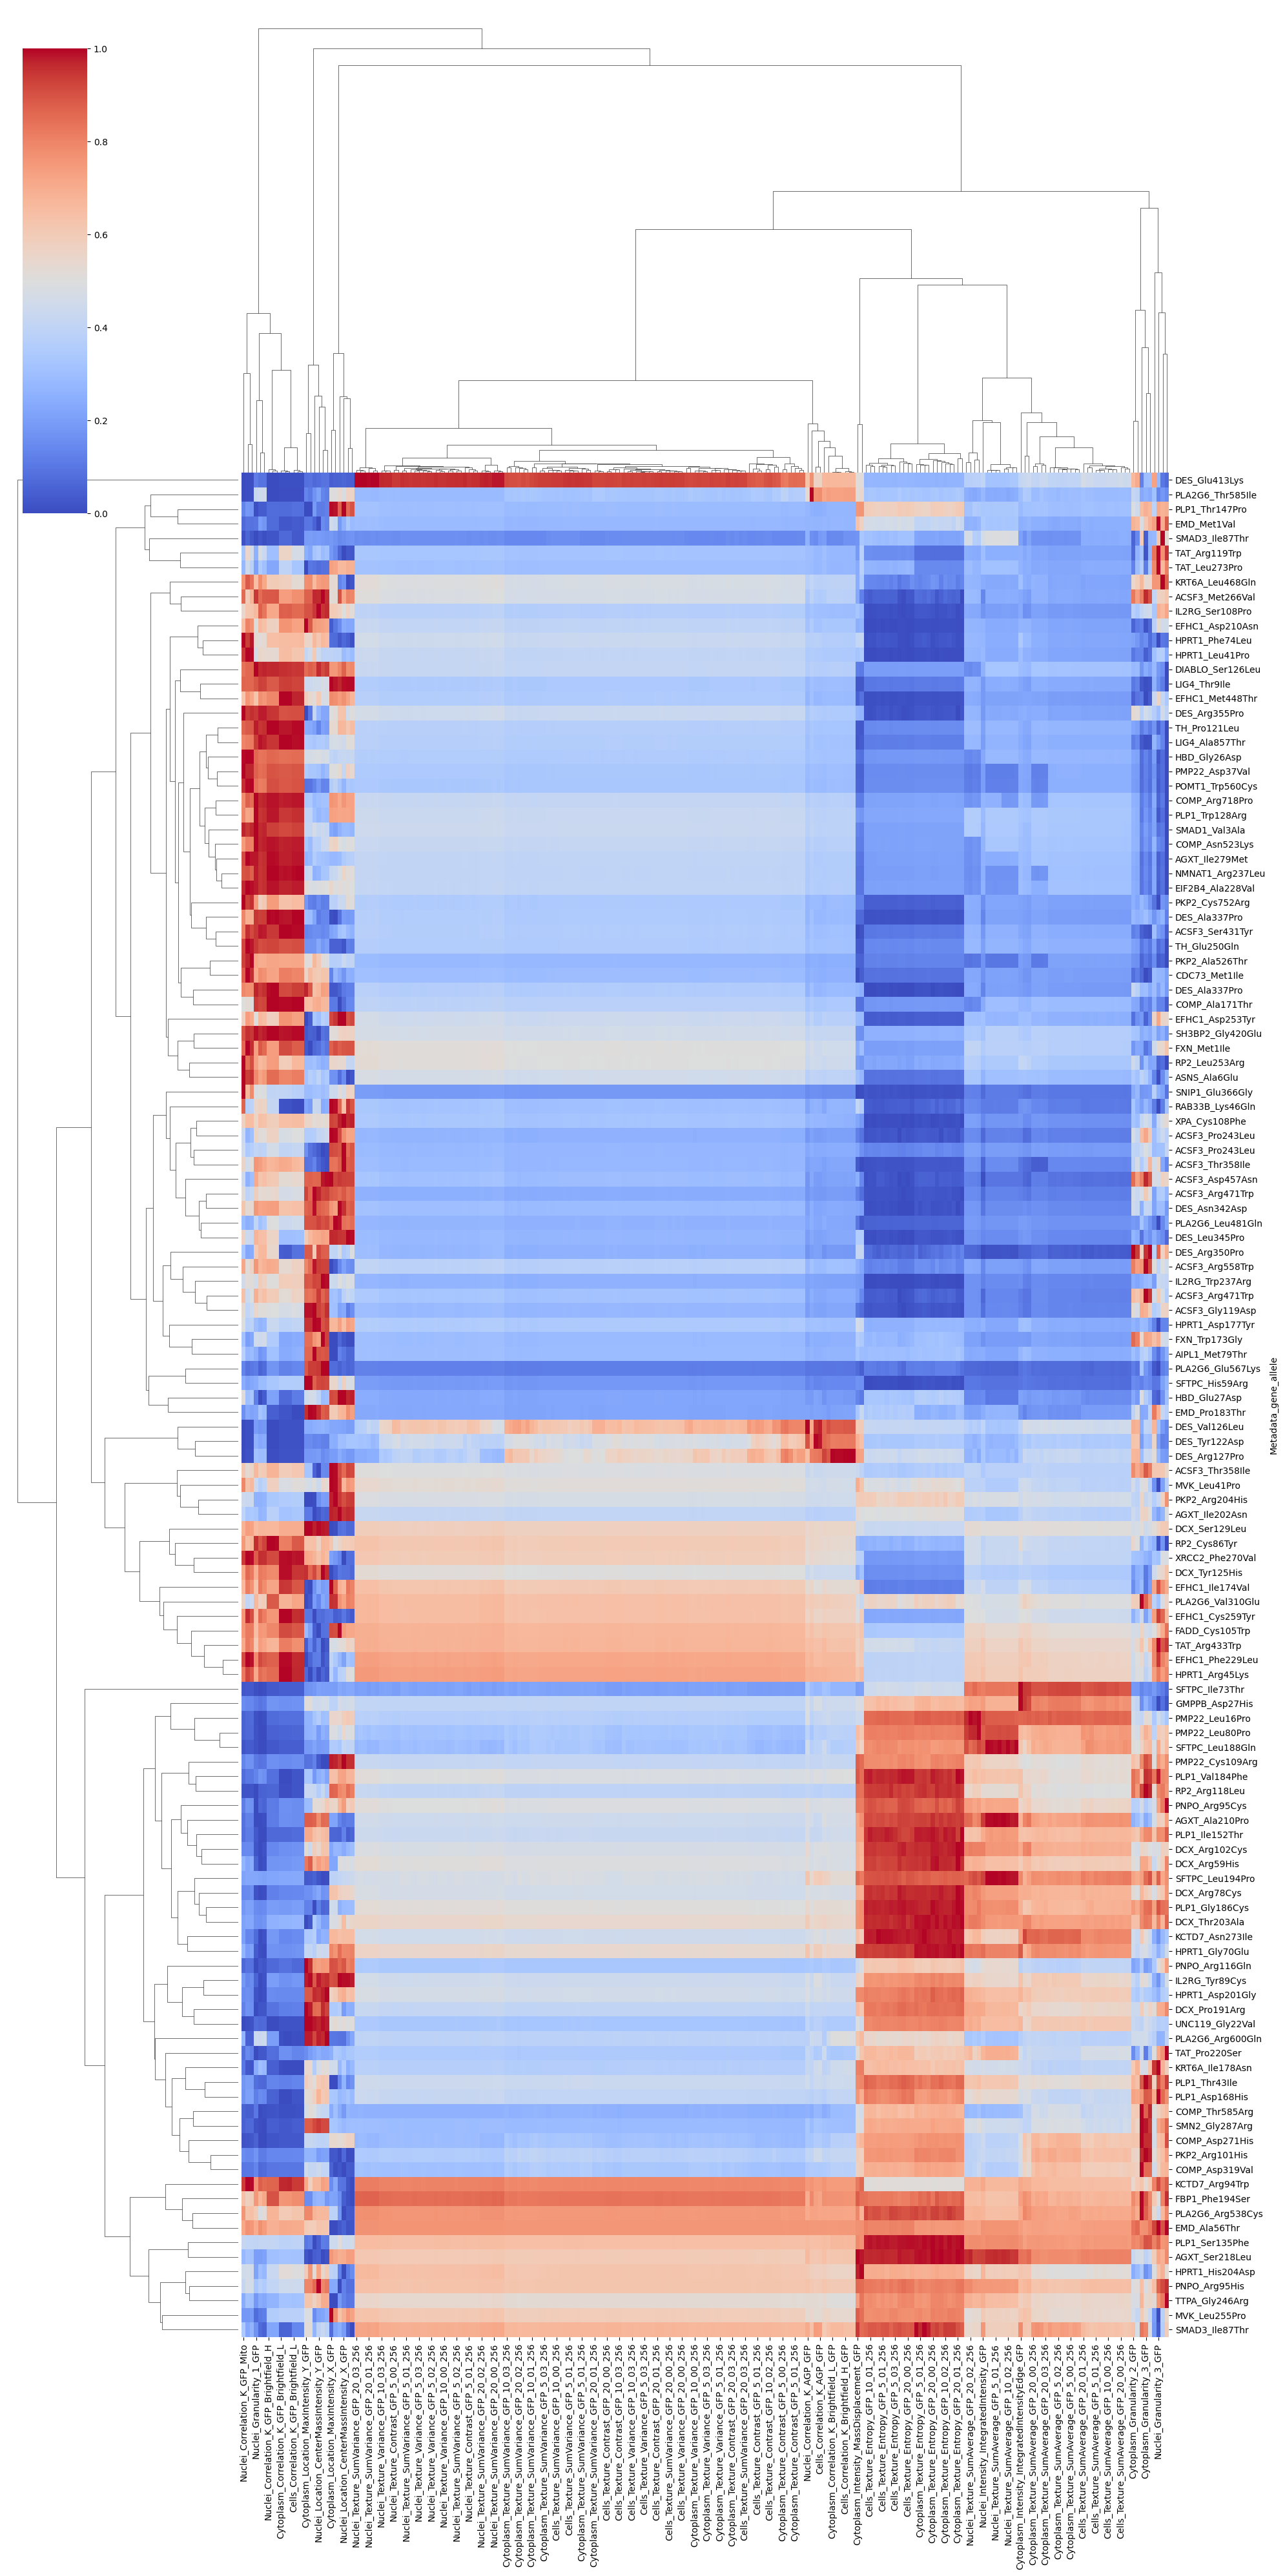

In [ ]:
from sklearn.preprocessing import StandardScaler

well_profiles_merge_plate = well_profiles.group_by(["Metadata_gene_allele", "Metadata_Well"]).agg(
    pl.col(col).median().alias(col)
        for col in profiles.columns
        if not col.startswith("Metadata_")
).unique()

gfp_cols = [col for col in well_profiles_merge_plate.columns if "GFP" in col]
well_profiles_merge_plate = well_profiles_merge_plate.select(
    [col for col in gfp_cols if well_profiles_merge_plate[col].std() > 2] + ["Metadata_gene_allele"]
)

scaler = StandardScaler()
well_profiles_merge_plate = well_profiles_merge_plate.select(
    [col for col in well_profiles_merge_plate.columns if not col.startswith("Metadata_")] + ["Metadata_gene_allele"]
).to_pandas().set_index("Metadata_gene_allele").loc[misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"],:]

well_profiles_scaled = pd.DataFrame(scaler.fit_transform(well_profiles_merge_plate), columns=well_profiles_merge_plate.columns, index=well_profiles_merge_plate.index)
display(well_profiles_scaled)

sns.clustermap(well_profiles_scaled, figsize=(20, 40), standard_scale=0, cmap="coolwarm", row_cluster=True, col_cluster=True) ## , "viridis"
plt.show()